# Plot

* 선그래프

In [67]:
import pandas as pd   # pandas 를 pd 라는 짧은 이름으로 불러오기

In [68]:


# 남북한 발전 전력량 엑셀 읽기 (engine='openpyxl' = .xlsx 를 여는 도구)
df = pd.read_excel('./Data-Pandas/남북한발전전력량.xlsx', engine='openpyxl')

# iloc[행, 열] : 번호로 고르기
#   [0, 5] = 0번 행(남한 합계), 5번 행(북한 합계)
#   2:     = 2번 열부터 끝까지 (앞의 글자 열 2개를 빼고 1990 ~ 2016 연도 열만)
df_ns = df.iloc[[0,5],2:]
df_ns

,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
0,1077,1186,1310,1444,1650,1847,2055,2244,2153,2393,...,4031,4224,4336,4747,4969,5096,5171,5220,5281,5404
5,277,263,247,221,231,230,213,193,170,186,...,236,255,235,237,211,215,221,216,190,239


In [69]:
# 행 인덱스 변경 :'South' , 'North'
#   0, 5 라는 번호 대신 알아보기 쉬운 이름으로 (행 개수와 이름 개수가 같아야 함)
df_ns.index=['South','North']
df_ns.head()   # 앞 5행 미리보기 (행이 2개뿐이라 전부 보임)


,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
South,1077,1186,1310,1444,1650,1847,2055,2244,2153,2393,...,4031,4224,4336,4747,4969,5096,5171,5220,5281,5404
North,277,263,247,221,231,230,213,193,170,186,...,236,255,235,237,211,215,221,216,190,239


<Axes: >

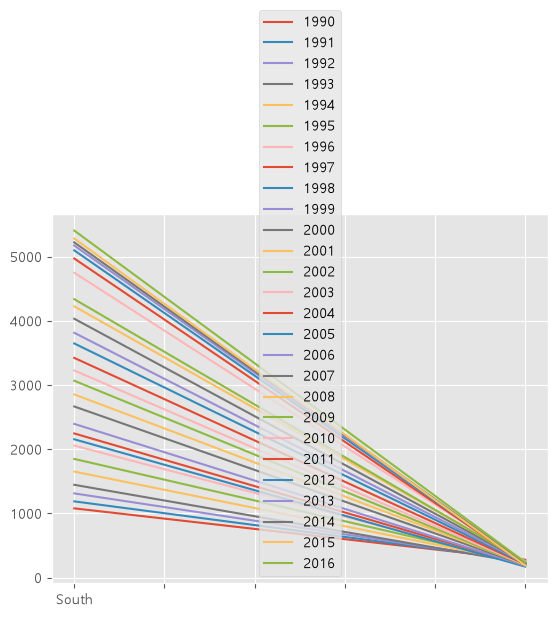

In [70]:
# 선 그래프 그리기
    # 행 인덱스 x축, 열 인덱스 y축
    #   → x축 = South, North / 선 = 연도마다 하나씩(27개) 이라 알아보기 어렵다
    #   plot() 은 kind 를 안 쓰면 선 그래프(kind='line')

df_ns.plot()

In [71]:
# 행, 열 전치하여 다시 그리기
#   .T = 행과 열 맞바꾸기 → 행 = 연도, 열 = South, North
#   (plot 은 행 인덱스를 x축으로 쓰므로, 연도를 x축에 놓으려면 뒤집어야 한다)

tdf_ns = df_ns.T
print(tdf_ns.head())


     South North
1990  1077   277
1991  1186   263
1992  1310   247
1993  1444   221
1994  1650   231


<Axes: >

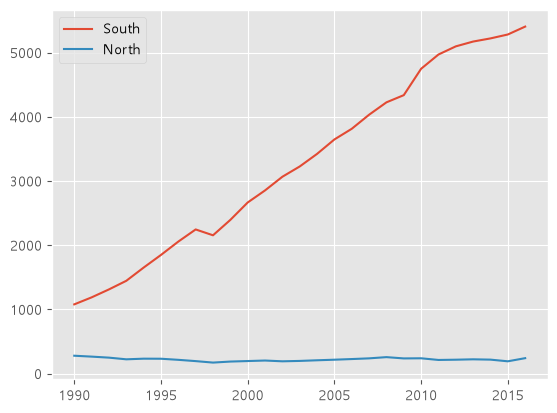

In [72]:
# 전치한 표로 선 그래프 → x축 = 연도, 선 2개(South, North) : 연도별 변화가 잘 보인다
tdf_ns.plot()

* 막대 그래프

<Axes: >

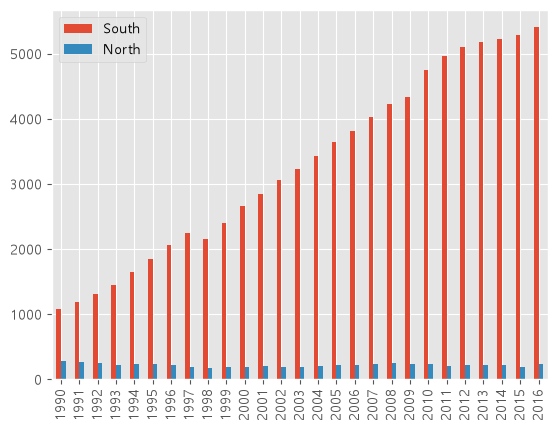

In [73]:
# kind='bar' : 막대 그래프 (연도마다 South, North 막대 2개씩)
#   가로 막대는 kind='barh'
tdf_ns.plot(kind='bar')

* 히스토그램

<Axes: ylabel='Frequency'>

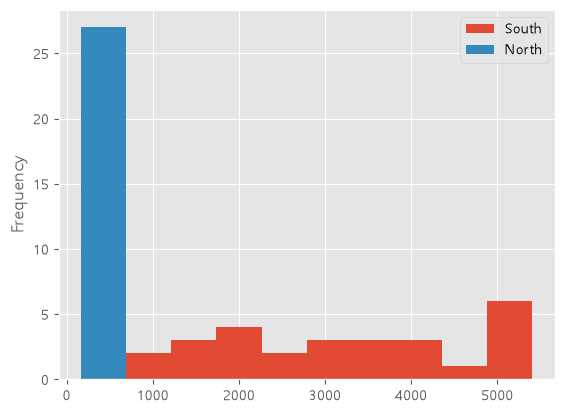

In [74]:
# 막대그래프는 데이터를 범주로 생각해서 문자열 그대로 사용가능
# 히스토그램은 숫자 구간 분포로 봄, 숫자로 변환해줘야함
#   pd.to_numeric() : 글자 취급(object)인 열 → 진짜 숫자로 변환
#   원본을 바꾸지 않으므로 = 로 다시 넣어야 반영된다
tdf_ns['North'] = pd.to_numeric(tdf_ns['North'])
tdf_ns['South'] = pd.to_numeric(tdf_ns['South'])

# kind='hist' : 히스토그램 = 값을 구간으로 나눠, 구간마다 몇 개 들어 있는지 센 그래프
#   x축 = 발전량 구간, y축(Frequency) = 그 구간에 속한 연도 수
tdf_ns.plot(kind='hist')

* 산점도

<Axes: xlabel='weight', ylabel='mpg'>

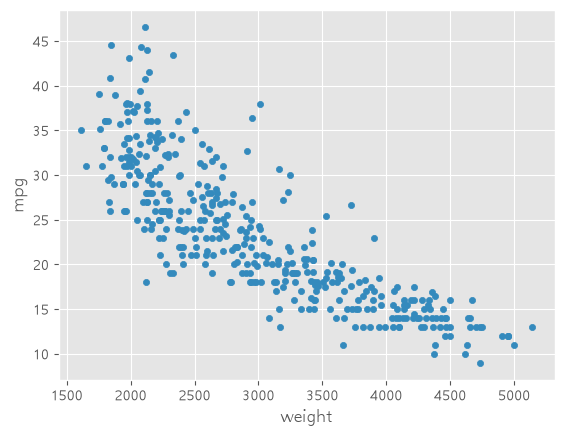

In [75]:
import pandas as pd

# 자동차 데이터 읽기 : 열 이름 줄이 없는 파일이라 header=None
df = pd.read_csv('./Data-Pandas/auto-mpg.csv', header=None)

# 열 이름 직접 붙이기 (mpg=연비, weight=무게 ...)
df.columns = ['mpg','cylinders','displacement','horsepower','weight',
              'acceleration','model year','origin','name']

# 2개의 열을 선택하여 산점도 그리기
#   kind='scatter' : 점 하나 = 자동차 1대 / x = 무게, y = 연비 (산점도는 x, y 를 꼭 지정)
#   점들이 오른쪽 아래로 내려간다 → 무거운 차일수록 연비가 나쁘다
df.plot(x='weight',y='mpg', kind='scatter')

* 박스플롯
    * 특정 변수의 데이터 분포와 분산정도에 대한 정보를 제공

<Axes: >

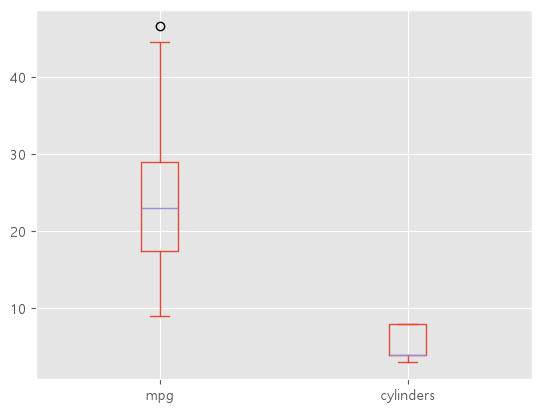

In [76]:
# 박스플롯 : 열 2개(mpg, cylinders)를 골라 [[ ]] 로 데이터프레임을 만든 뒤 그리기
#   상자 = 가운데 50% 가 모여 있는 범위(25% ~ 75%), 상자 안의 선 = 중앙값(50%)
#   위아래 수염 = 정상 범위의 최소·최대, 동그라미 = 유난히 튀는 값(이상치)
df[['mpg','cylinders']].plot(kind='box')

## matplotlib
 

* 선 그래프

In [77]:
import pandas as pd
import matplotlib.pyplot as plt   # matplotlib : 그래프를 세밀하게 꾸밀 수 있는 도구. 보통 plt 로 줄여 씀

# 시도별 전출입 인구수.xlsx
#   header=0 : 첫 줄을 열 이름으로 (전출지별, 전입지별, 1970, 1971 ...)
#   전출지 = 떠난 곳, 전입지 = 새로 들어간 곳
df=pd.read_excel('./Data-Pandas/시도별 전출입 인구수.xlsx',engine='openpyxl',header=0)
df

,전출지별,전입지별,1970,1971,1972,1973,1974,1975,1976,1977,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
0,전출지별,전입지별,이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),...,이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명)
1,전국,전국,4046536,4210164,3687938,4860418,5297969,9011440,6773250,7397623,...,8808256,8487275,8226594,8127195,7506691,7411784,7629098,7755286,7378430,7154226
2,NaN,서울특별시,1742813,1671705,1349333,1831858,2050392,3396662,2756510,2893403,...,2025358,1873188,1733015,1721748,1555281,1520090,1573594,1589431,1515602,1472937
3,NaN,부산광역시,448577,389797,362202,482061,680984,805979,724664,785117,...,514502,519310,519334,508043,461042,478451,485710,507031,459015,439073
4,NaN,대구광역시,-,-,-,-,-,-,-,-,...,409938,398626,370817,370563,348642,351873,350213,351424,328228,321182
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,NaN,전라북도,139,202,141,210,219,415,392,408,...,668,579,672,561,551,516,609,683,733,768
321,NaN,전라남도,631,965,857,952,1133,2808,2608,2652,...,1143,1123,1002,1026,966,1001,928,1062,1127,1102
322,NaN,경상북도,374,619,468,576,625,1123,1141,1004,...,761,704,738,756,699,781,728,903,931,994
323,NaN,경상남도,474,479,440,571,1208,1517,863,1122,...,1517,1474,1324,1367,1227,1278,1223,1500,1448,1501


In [78]:
#누락값(NaN)을 앞 데이터로 채움
#   엑셀의 병합 셀 때문에 '전출지별' 은 첫 칸만 값이 있고 아래는 NaN
#   ffill() = forward fill : 빈칸을 바로 위 칸의 값으로 채운다 (전국, NaN, NaN → 전국, 전국, 전국)
df = df.ffill()
df.head()

,전출지별,전입지별,1970,1971,1972,1973,1974,1975,1976,1977,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
0,전출지별,전입지별,이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),...,이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명),이동자수 (명)
1,전국,전국,4046536,4210164,3687938,4860418,5297969,9011440,6773250,7397623,...,8808256,8487275,8226594,8127195,7506691,7411784,7629098,7755286,7378430,7154226
2,전국,서울특별시,1742813,1671705,1349333,1831858,2050392,3396662,2756510,2893403,...,2025358,1873188,1733015,1721748,1555281,1520090,1573594,1589431,1515602,1472937
3,전국,부산광역시,448577,389797,362202,482061,680984,805979,724664,785117,...,514502,519310,519334,508043,461042,478451,485710,507031,459015,439073
4,전국,대구광역시,-,-,-,-,-,-,-,-,...,409938,398626,370817,370563,348642,351873,350213,351424,328228,321182


In [79]:
# '전출지별' 열만 꺼내 앞 5개 확인 → NaN 이 잘 채워졌는지 보기
df['전출지별'].head()  

0    전출지별
1      전국
2      전국
3      전국
4      전국
Name: 전출지별, dtype: str

In [80]:
# 서울에서 다른 지역으로 이동한 데이터만 추출하여 정리
#   mask = 행마다 조건에 맞으면 True, 아니면 False 인 목록 (불린 시리즈)
#   조건1 : 전출지가 서울  /  조건2 : 전입지는 서울이 아님 (서울 → 서울 제외)
#   & = 그리고(and). 조건마다 괄호 ( ) 로 꼭 감싸야 한다

mask = (df['전출지별'] == '서울특별시') & (df['전입지별'] != '서울특별시')
mask.head()

0    False
1    False
2    False
3    False
4    False
dtype: bool

In [81]:
# 서울에서 다른 지역으로 이동한 데이터만 추출하여 정리
mask = (df['전출지별'] == '서울특별시')  & (df['전입지별'] != '서울특별시')
# mask.head()

# df[mask] : mask 가 True 인 행만 남긴다 (불린 인덱싱)
df_seoul = df[mask]
# df_seoul.head()

# 전출지별 삭제 (전부 '서울특별시' 라 더 필요 없음 / axis=1 = 열 삭제)
df_seoul = df_seoul.drop(['전출지별'], axis=1)
# df_seoul.head()

# 전입지별 이름을 전입지로 바꾸기
df_seoul = df_seoul.rename(columns={'전입지별':'전입지'})

# 전입지 열을 행 인덱스로 → df_seoul.loc['경기도'] 처럼 지역 이름으로 행을 찾을 수 있다
df_seoul.set_index('전입지',inplace=True)
df_seoul.head()

,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
전입지,,,,,,,,,,,,,,,,,,,,,
전국,1448985,1419016,1210559,1647268,1819660,2937093,2495620,2678007,3028911,2441242,...,2083352,1925452,1848038,1834806,1658928,1620640,1661425,1726687,1655859,1571423
부산광역시,11568,11130,11768,16307,22220,27515,23732,27213,29856,28542,...,17353,17738,17418,18816,16135,16153,17320,17009,15062,14484
대구광역시,-,-,-,-,-,-,-,-,-,-,...,9720,10464,10277,10397,10135,10631,10062,10191,9623,8891
인천광역시,-,-,-,-,-,-,-,-,-,-,...,50493,45392,46082,51641,49640,47424,43212,44915,43745,40485
광주광역시,-,-,-,-,-,-,-,-,-,-,...,10846,11725,11095,10587,10154,9129,9759,9216,8354,7932


In [82]:
# 서울에서 경기도로 이동한 인구 데이터 값만 선택
#   loc['경기도'] : 행 하나를 꺼냄 → 시리즈 (인덱스 = 연도, 값 = 이동한 사람 수)
sr_one = df_seoul.loc['경기도']
sr_one.head()

1970    130149
1971    150313
1972     93333
1973    143234
1974    149045
Name: 경기도, dtype: object

In [83]:
# 시리즈의 인덱스 확인 → '1970' ~ '2017' (숫자가 아니라 글자로 된 연도)
sr_one.index

Index(['1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978',
       '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987',
       '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996',
       '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005',
       '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014',
       '2015', '2016', '2017'],
      dtype='str')

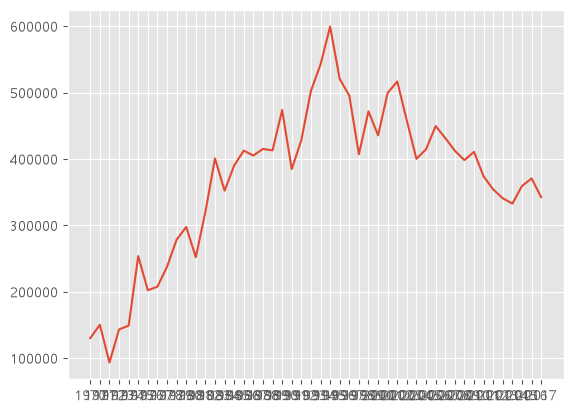

In [84]:
# 시리즈의 index를 x값으로, data값을 y로 설정
#   plt.plot(x, y) : 선 그래프 / x = 연도, y = 이동 인구수
plt.plot(sr_one.index, sr_one.values)


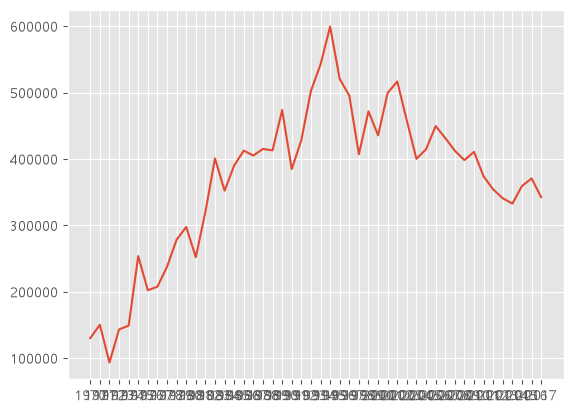

In [85]:
plt.plot(sr_one) # 시리즈나 데이터프레임 객체를 바로 넣어도 됨 (인덱스가 x, 값이 y 로 자동 지정)

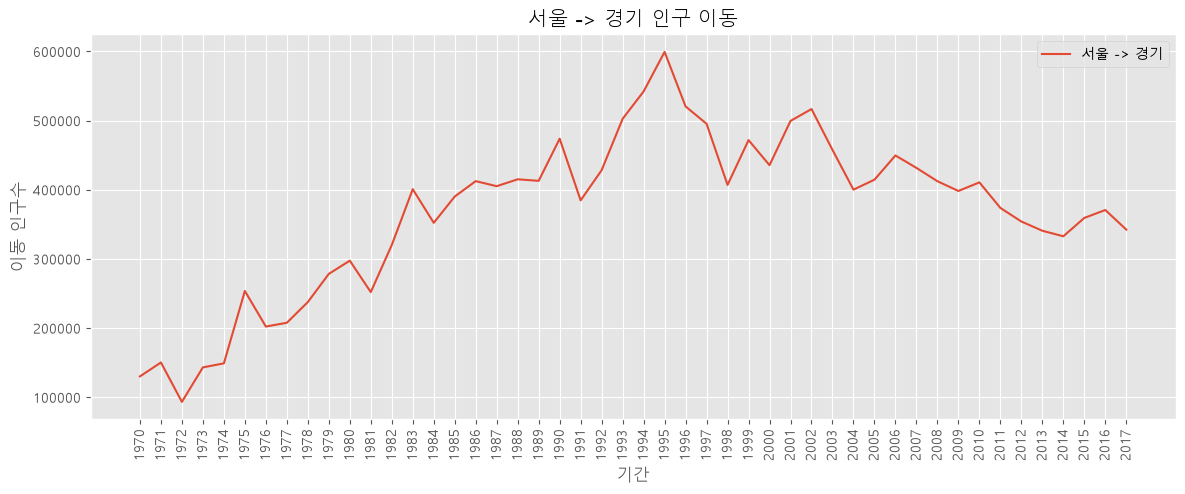

In [86]:
# 한글 글꼴 설정 : matplotlib 기본 글꼴에는 한글이 없어 □□□ 로 깨지기 때문
from matplotlib import font_manager , rc

font_path = './Data-Pandas/malgun.ttf'                                # 글꼴 파일(맑은 고딕) 위치
font_name = font_manager.FontProperties(fname=font_path).get_name()   # 파일에서 글꼴 이름 꺼내기 → 'Malgun Gothic'
rc('font', family =  font_name)                                        # 앞으로 그리는 모든 그래프의 글꼴로 설정

# 그림 사이즈 지정(가로 14인치, 세로 5인치)
#   plot 보다 먼저 써야 한다 (도화지 크기를 먼저 정하고 그 위에 그림)
plt.figure(figsize=(14,5))

# x축 눈금 라벨 회전하기
#   'vertical' = 세로(90도), 'horizontal' = 가로, 또는 숫자(각도). 소문자로 써야 한다
plt.xticks(rotation = 'vertical') # rotation=30 반시계방향

plt.plot(sr_one.index , sr_one.values)   # 선 그래프 : x = 연도, y = 이동 인구수
plt.title('서울 -> 경기 인구 이동')       # 그래프 제목

#축이름
plt.xlabel('기간')          # x축 이름
plt.ylabel('이동 인구수')    # y축 이름

# 범례 : 선이 무엇을 뜻하는지 알려 주는 이름표 / loc = 범례 위치 ('best' = 선을 안 가리는 자리 자동 선택)
plt.legend(labels = ['서울 -> 경기'], loc='best')
# plt.legend(labels=['서울 -> 경기'], loc=0)   # 최적 위치
# plt.legend(labels=['서울 -> 경기'], loc=1)   # 오른쪽 위
# plt.legend(labels=['서울 -> 경기'], loc=2)   # 왼쪽 위
# plt.legend(labels=['서울 -> 경기'], loc=3)   # 왼쪽 아래
# plt.legend(labels=['서울 -> 경기'], loc=4)   # 오른쪽 아래
# plt.legend(labels=['서울 -> 경기'], loc=5)   # 오른쪽
# plt.legend(labels=['서울 -> 경기'], loc=6)   # 왼쪽 중앙
# plt.legend(labels=['서울 -> 경기'], loc=7)   # 오른쪽 중앙
# plt.legend(labels=['서울 -> 경기'], loc=8)   # 아래쪽 중앙
# plt.legend(labels=['서울 -> 경기'], loc=9)   # 위쪽 중앙
# plt.legend(labels=['서울 -> 경기'], loc=10)  # 가운데
plt.show()   # 완성된 그래프를 화면에 출력

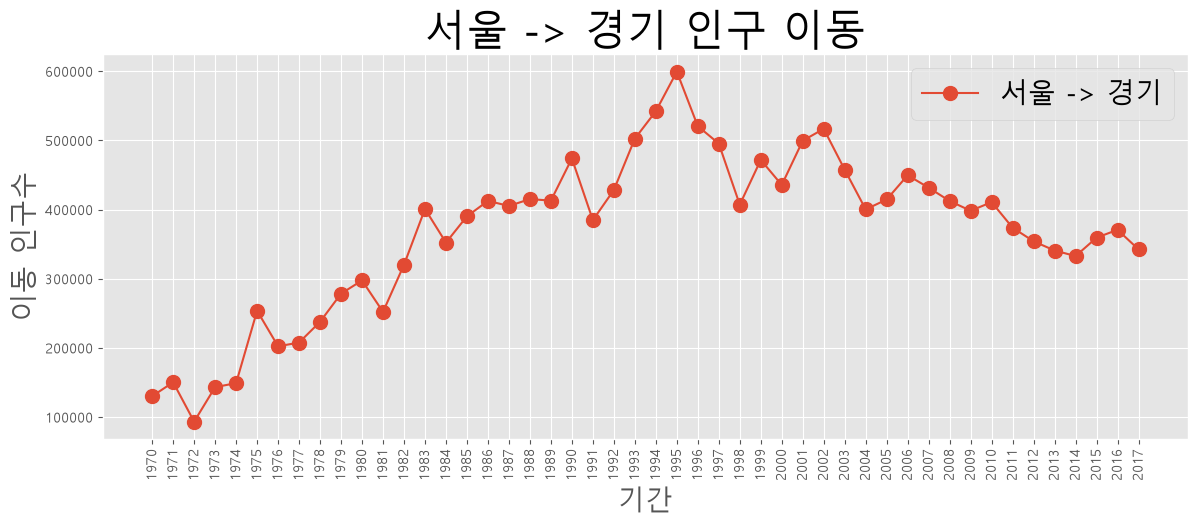

In [87]:
# 위 그래프를 더 보기 좋게 꾸미기 (글자 크기, 점 표시 추가)
plt.figure(figsize=(14,5))   # 그림 크기 : 가로 14인치, 세로 5인치

plt.xticks(size = 10, rotation='vertical')   # x축 눈금 : 글자 크기 10, 세로로 회전

# marker='o' : 값이 있는 자리마다 동그란 점 표시 / markersize = 점 크기
plt.plot(sr_one.index, sr_one.values, marker='o', markersize=10)


plt.title("서울 -> 경기 인구 이동", size = 30)   # 제목 (size = 글자 크기)
plt.xlabel("기간", size = 20)                    # x축 이름
plt.ylabel("이동 인구수", size = 20)              # y축 이름

# 범례 : labels(복수형 s 주의) = 선의 이름표, fontsize = 범례 글자 크기
plt.legend(labels=['서울 -> 경기'], loc='best', fontsize = 20)
plt.show()   # 완성된 그래프 출력


* 서울에서 '충청남도 경상북도, 강원도, 전라남도 로 이동한 인구 데이터 값

In [88]:

# 여기부터 다시 시작해도 되도록 데이터 준비 과정을 한 셀에 모음
import pandas as pd
import matplotlib.pyplot as plt

# 시도별 전출입 인구수 엑셀 읽기 (header=0 : 첫 줄이 열 이름)
df=pd.read_excel('./Data-Pandas/시도별 전출입 인구수.xlsx',engine='openpyxl',header=0)

# 병합 셀 때문에 생긴 NaN 을 바로 위 칸의 값으로 채우기
df = df.ffill()


# ※ 아래 두 줄은 바로 밑에서 mask 를 다시 만들기 때문에 없어도 결과가 같다
#   (mask.head() 는 셀의 마지막 줄이 아니라서 화면에 출력되지도 않음)
mask = (df['전출지별'] == '서울특별시') & (df['전입지별'] != '서울특별시')
mask.head()

# 서울에서 다른 지역으로 이동한 데이터만 추출하여 정리
#   조건1 : 전출지가 서울 / 조건2 : 전입지는 서울이 아님 / & = 그리고
mask = (df['전출지별'] == '서울특별시')  & (df['전입지별'] != '서울특별시')
# mask.head()


# df[mask] : mask 가 True 인 행만 남긴다 (불린 인덱싱)
df_seoul = df[mask]
# df_seoul.head()

# 전출지별 삭제 (전부 '서울특별시' 라 더 필요 없음 / axis=1 = 열 삭제)
df_seoul = df_seoul.drop(['전출지별'], axis=1)
# df_seoul.head()

# 전입지별 이름을 전입지로 바꾸기
df_seoul = df_seoul.rename(columns={'전입지별':'전입지'})

# 전입지 열을 행 인덱스로 → df_seoul.loc['경기도'] 처럼 지역 이름으로 행을 찾을 수 있다
df_seoul.set_index('전입지',inplace=True)
df_seoul.head()   # 앞 5행 미리보기





,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
전입지,,,,,,,,,,,,,,,,,,,,,
전국,1448985,1419016,1210559,1647268,1819660,2937093,2495620,2678007,3028911,2441242,...,2083352,1925452,1848038,1834806,1658928,1620640,1661425,1726687,1655859,1571423
부산광역시,11568,11130,11768,16307,22220,27515,23732,27213,29856,28542,...,17353,17738,17418,18816,16135,16153,17320,17009,15062,14484
대구광역시,-,-,-,-,-,-,-,-,-,-,...,9720,10464,10277,10397,10135,10631,10062,10191,9623,8891
인천광역시,-,-,-,-,-,-,-,-,-,-,...,50493,45392,46082,51641,49640,47424,43212,44915,43745,40485
광주광역시,-,-,-,-,-,-,-,-,-,-,...,10846,11725,11095,10587,10154,9129,9759,9216,8354,7932


In [89]:
# 서울에서 충청남도, 경상북도, 강원도, 전라남도로 이동한 데이터만 선택
#   지역이 여러 개라 이름을 리스트 [ ] 로 한 번 더 감싼다 → 결과는 데이터프레임 (4행 x 48열)
df_4 = df_seoul.loc[['충청남도','경상북도','강원도','전라남도']]

# transpose() = .T : 행과 열 맞바꾸기 → 행 = 연도, 열 = 지역
#   plot 은 행 인덱스를 x축으로 쓰므로, 연도를 x축에 놓으려면 뒤집어야 한다
df_4 = df_4.transpose()
df_4.head()

전입지,충청남도,경상북도,강원도,전라남도
1970,15954,11868,9352,10513
1971,18943,16459,12885,16755
1972,23406,22073,13561,20157
1973,27139,27531,16481,22160
1974,25509,26902,15479,21314


In [90]:
# testcode  : 그래프 스타일 종류
#   plt.style.available = 쓸 수 있는 스타일 이름 목록 (리스트)
#   이 중 하나를 골라 plt.style.use('이름') 으로 적용한다
print(plt.style.available)

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


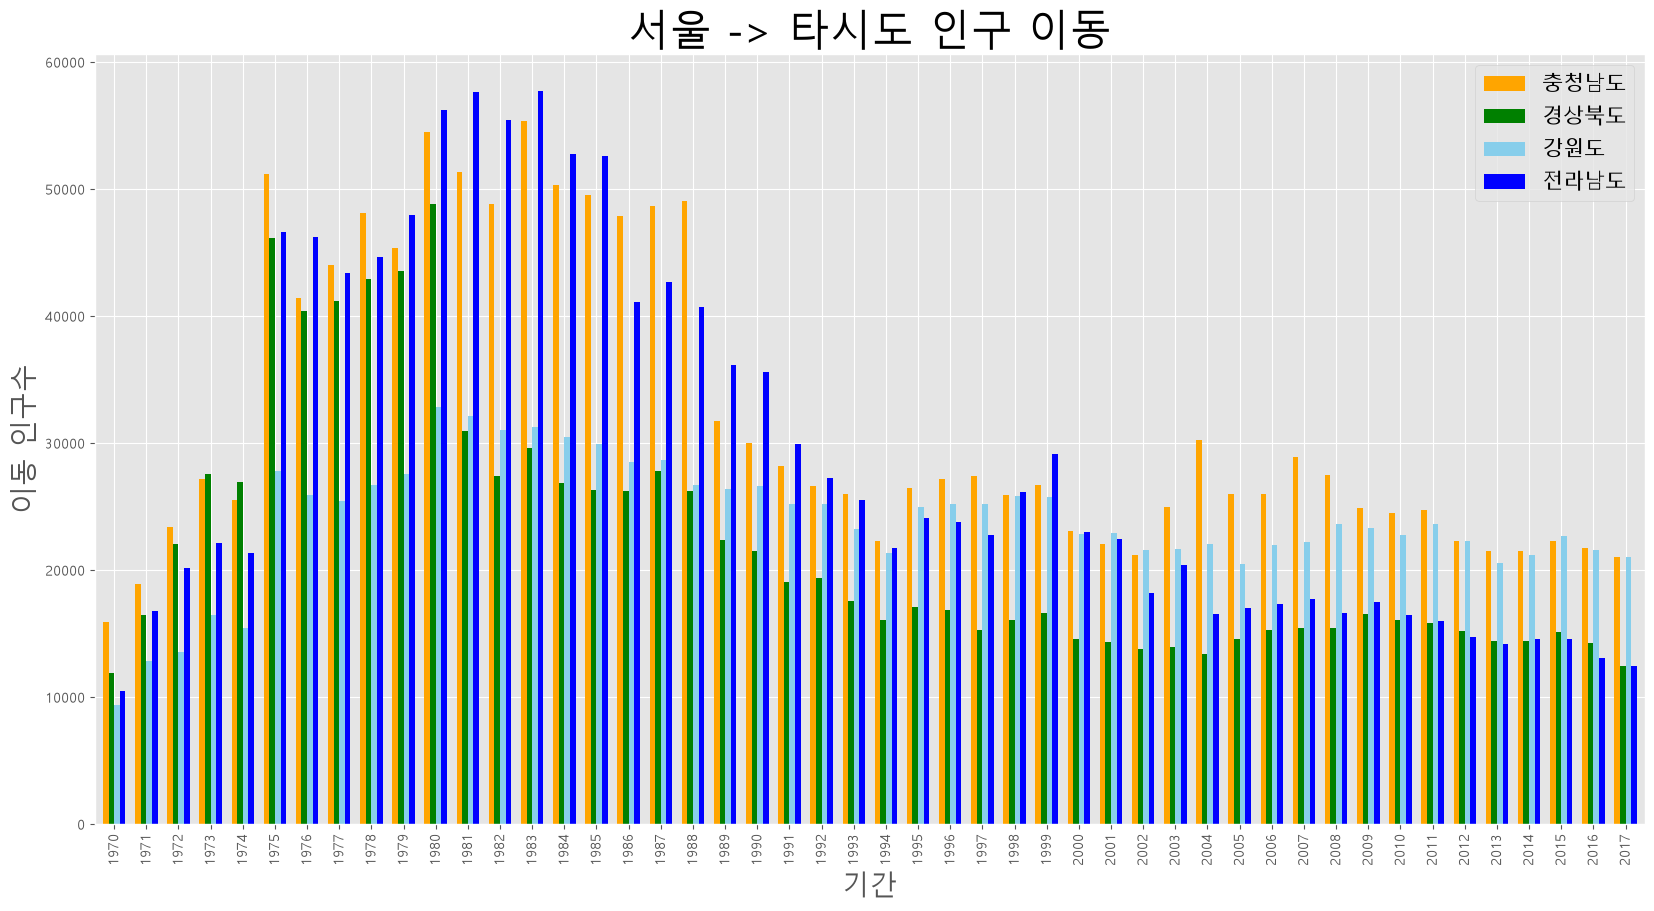

In [91]:
# 그래프 스타일 적용 : 'ggplot' = 회색 배경 + 흰 격자선
#   한 번 적용하면 이후에 그리는 그래프에도 계속 적용된다
plt.style.use('ggplot')

# 막대 그래프 그리기
#   kind='bar' : 연도마다 지역 4개의 막대를 나란히 그림
#   figsize=(20,10) : 그림 크기 / color : 열 순서대로(충남, 경북, 강원, 전남) 막대 색 지정
df_4.plot(kind='bar',figsize=(20,10),width = 0.7,
          color = ['orange','green','skyblue','blue']) # width = 0.7 : 막대너비, 기본은 0.8

plt.title("서울 -> 타시도 인구 이동", size = 30)   # 제목
plt.xlabel("기간", size = 20)                      # x축 이름
plt.ylabel("이동 인구수", size = 20)                # y축 이름

# 범례 : labels 를 안 쓰면 열 이름(지역 이름)이 자동으로 들어간다
plt.legend(loc='best', fontsize = 15)
plt.show()



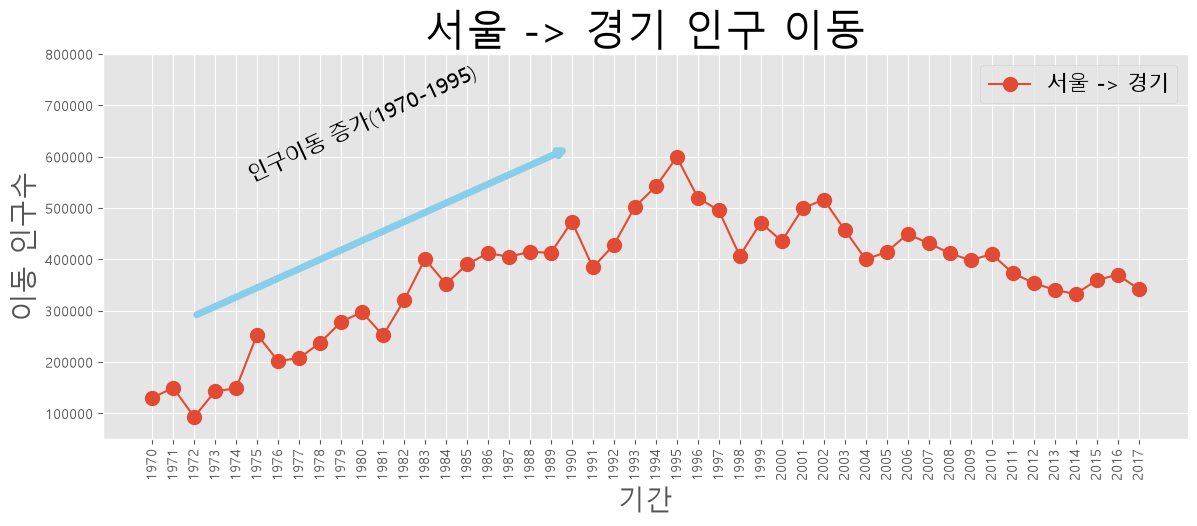

In [92]:
# 그래프에 주석 달기 : annotation
#   annotate = 그래프 위에 화살표나 글자를 그려 넣어 설명을 덧붙이는 기능

# 서울 → 경기도 이동 데이터 (시리즈 : 인덱스 = 연도, 값 = 이동 인구수)
sr_one = df_seoul.loc['경기도']

# 스타일 서식 지정
plt.style.use('ggplot')

plt.figure(figsize=(14, 5))                # 그림 크기
plt.xticks(size=10, rotation='vertical')   # x축 눈금 글자 크기 10, 세로 회전

plt.plot(sr_one.index, sr_one.values, marker='o', markersize=10)   # 점이 찍힌 선 그래프

plt.title('서울 -> 경기 인구 이동', size=30) #차트 제목
plt.xlabel('기간', size=20)#x축 이름
plt.ylabel('이동 인구수', size=20)#y축 이름

plt.legend(labels=['서울 -> 경기'], loc='best', fontsize=15)

# y축 범위 지정(최소값, 최대값) : 주석을 넣을 공간 확보
plt.ylim(50000,800000)

# 주석 표시 - 화살표
#   글자 없이('') 화살표만 그린다 : xytext(시작점) → xy(끝점, 화살촉)
#   좌표 (x, y) : x = 왼쪽부터 몇 번째 눈금인지 (0 = 1970, 2 = 1972, 20 = 1990), y = 인구수
plt.annotate('',
             xy=(20,620000),        # 화살표 끝점 (화살촉이 가리키는 곳)
             xytext=(2,290000),     # 화살표 시작점
             xycoords='data',       # 좌표를 그래프의 데이터 값 기준으로 해석
             arrowprops=dict(arrowstyle="->", color = 'skyblue', lw=5), # 화살표 서식 (모양, 색, 선 굵기)
             )

# 주석 표시 - 텍스트
#   화살표 없이 글자만 표시. xy = 글자가 놓일 위치
plt.annotate('인구이동 증가(1970-1995)',
              xy=(10,550000),       # 글자 위치 (10번째 눈금 = 1980, 인구수 550000)
              rotation=25,          # 글자를 25도 기울임 (화살표 기울기에 맞춤)
              va='baseline',        # 세로 정렬 : 글자의 밑줄 기준
              ha='center',          # 가로 정렬 : xy 위치가 글자의 가운데
              fontsize = 15,)

plt.show()

In [ ]:
### 서울에서 '충청남도','경상북도', '강원도'로 이동한 인구 데이터 값만 선택
col_years = list(map(str, range(1970,2018)))
df_3 = df_seoul.loc[['충청남도','경상북도','강원도'], col_years]
df_3.head()

,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
전입지,,,,,,,,,,,,,,,,,,,,,
충청남도,15954,18943,23406,27139,25509,51205,41447,43993,48091,45388,...,27458,24889,24522,24723,22269,21486,21473,22299,21741,21020
경상북도,11868,16459,22073,27531,26902,46177,40376,41155,42940,43565,...,15425,16569,16042,15818,15191,14420,14456,15113,14236,12464
강원도,9352,12885,13561,16481,15479,27837,25927,25415,26700,27599,...,23668,23331,22736,23624,22332,20601,21173,22659,21590,21016


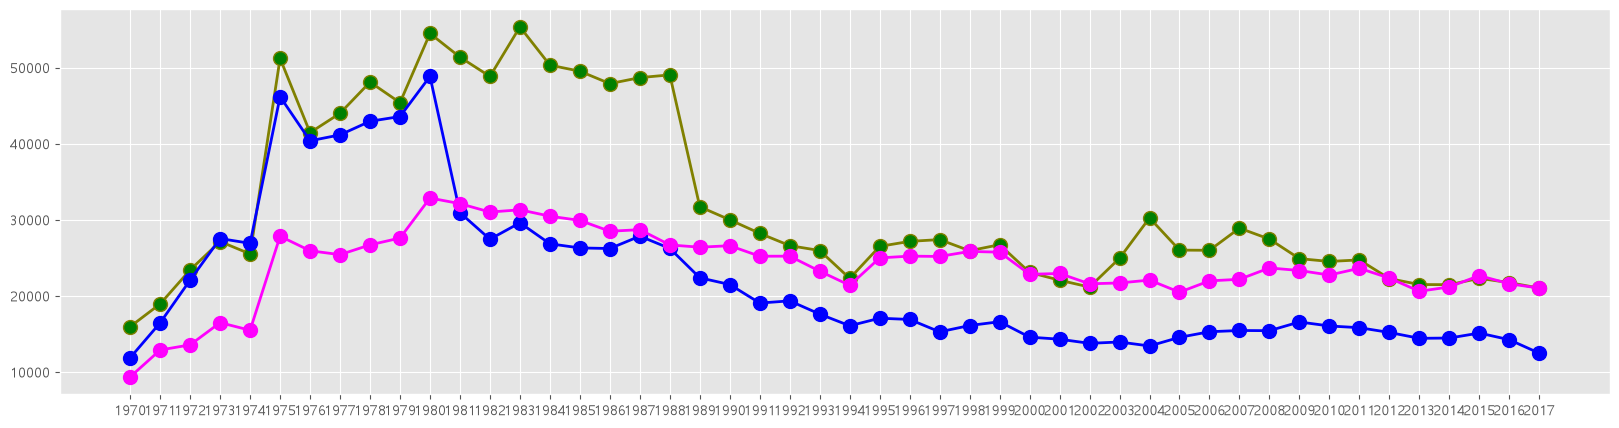

In [94]:
plt.style.use('ggplot')

fig = plt.figure(figsize=(20,5))
ax = fig.add_subplot(1,1,1)

ax.plot(col_years ,df_3.loc['충청남도',:], marker='o', markerfacecolor = 'green',
        markersize = 10, color ='olive', linewidth = 2, label = '서울 -> 충남')
ax.plot(col_years ,df_3.loc['경상북도',:], marker='o', markerfacecolor = 'blue',
        markersize = 10, color ='blue', linewidth = 2, label = '서울 -> 경북')
ax.plot(col_years ,df_3.loc['강원도',:], marker='o', markerfacecolor = 'magenta',
        markersize = 10, color ='magenta', linewidth = 2, label = '서울 -> 강원')

In [95]:
# 범례 표시
ax.legend(loc='best')

# 차트 제목 추가
ax.set_title('서울 -> 충남, 경북, 강원 인구 이동', size=20)

# 축이름 추가
ax.set_xlabel('기간', size=12)
ax.set_ylabel('이동 인구수', size = 12)

# 축 눈금 라벨 지정 및 90도 회전
# ax.set_xticklabels(col_years, rotation=70)
ax.tick_params(axis="x", labelsize=10, labelrotation=70) 
# 축 눈금 라벨 크기
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=10)

plt.show()




* 화면분할하여 그래프 여러개 그리기

C:\Users\hooho\AppData\Local\Temp\ipykernel_22636\1832292821.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(col_years, rotation=90)
C:\Users\hooho\AppData\Local\Temp\ipykernel_22636\1832292821.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(col_years, rotation=90)
C:\Users\hooho\AppData\Local\Temp\ipykernel_22636\1832292821.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax3.set_xticklabels(col_years, rotation=90)
C:\Users\hooho\AppData\Local\Temp\ipykernel_22636\1832292821.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_tic

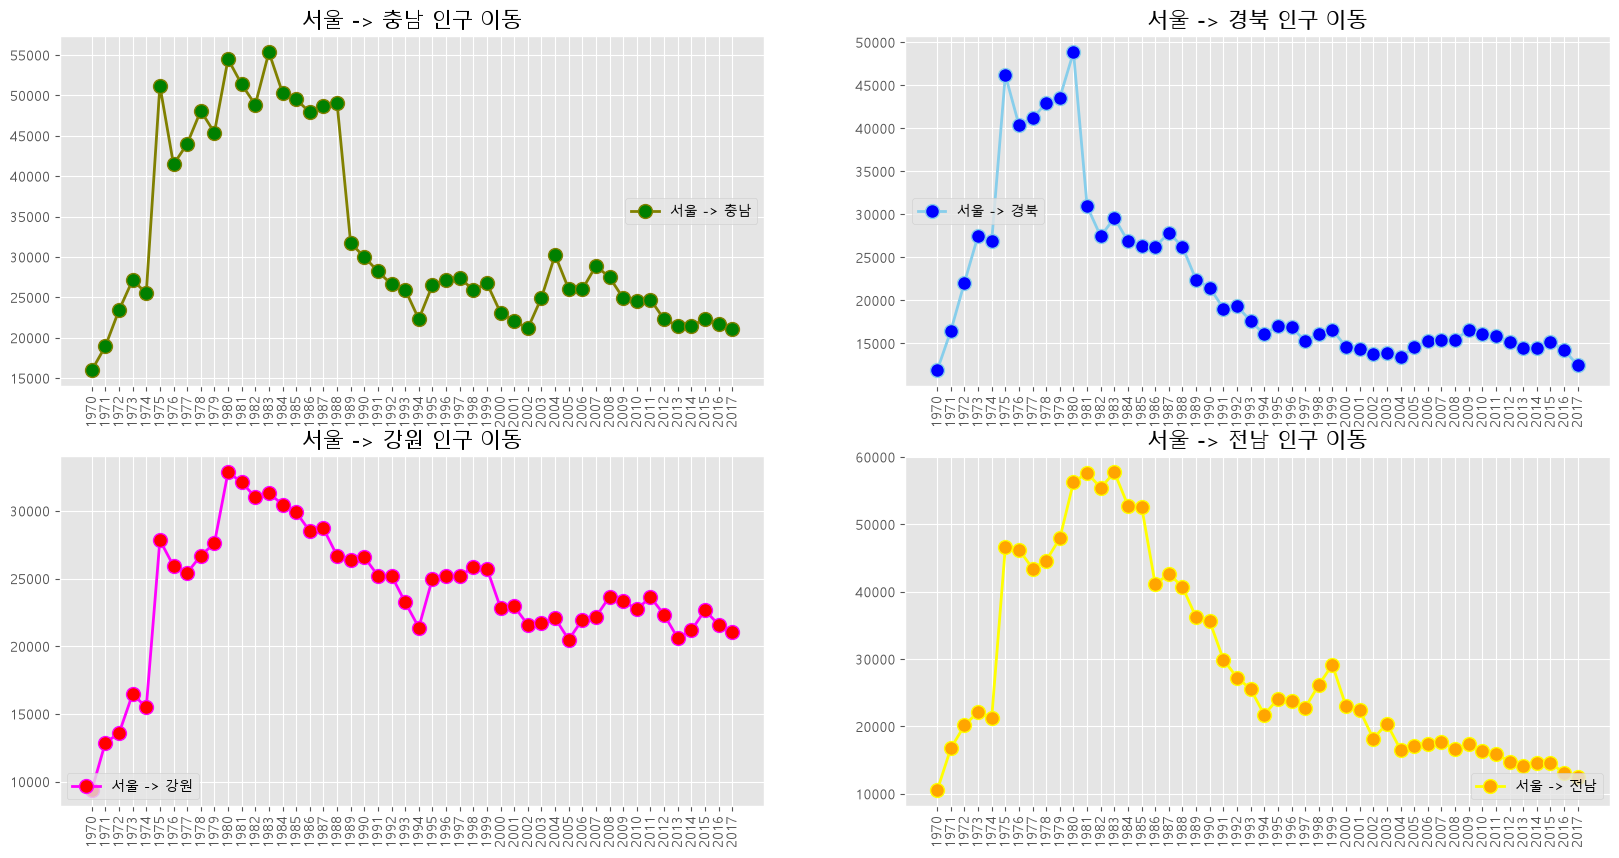

In [97]:
df_4 = df_seoul.loc[['충청남도','경상북도', '강원도', '전라남도'], col_years]

plt.style.use('ggplot')

# 그래프 객체 생성
fig = plt.figure(figsize=(20, 10))
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3)
ax4 = fig.add_subplot(2, 2, 4)

ax1.plot(col_years, df_4.loc['충청남도',:], marker='o', markerfacecolor='green',
         markersize=10, color='olive', linewidth=2, label='서울 -> 충남')
ax2.plot(col_years, df_4.loc['경상북도',:], marker='o', markerfacecolor='blue',
         markersize=10, color='skyblue', linewidth=2, label='서울 -> 경북')
ax3.plot(col_years, df_4.loc['강원도',:], marker='o', markerfacecolor='red',
         markersize=10, color='magenta', linewidth=2, label='서울 -> 강원')
ax4.plot(col_years, df_4.loc['전라남도',:], marker='o', markerfacecolor='orange',
         markersize=10, color='yellow', linewidth=2, label='서울 -> 전남')

# 범례 표시
ax1.legend(loc=5)
ax2.legend(loc=6)
ax3.legend(loc=3)
ax4.legend(loc=4)

# 차트 제목 추가
ax1.set_title('서울 -> 충남 인구 이동', size=15)
ax2.set_title('서울 -> 경북 인구 이동', size=15)
ax3.set_title('서울 -> 강원 인구 이동', size=15)
ax4.set_title('서울 -> 전남 인구 이동', size=15)

# 축 눈금 라벨 지정 및 90도 회전
ax1.set_xticklabels(col_years, rotation=90)
ax2.set_xticklabels(col_years, rotation=90)
ax3.set_xticklabels(col_years, rotation=90)
ax4.set_xticklabels(col_years, rotation=90)

plt.show()

* color table

In [98]:
import matplotlib

colors={}
for name, hex in matplotlib.colors.cnames.items():
    colors[name] = hex
    
print(colors)

{'aliceblue': '#F0F8FF', 'antiquewhite': '#FAEBD7', 'aqua': '#00FFFF', 'aquamarine': '#7FFFD4', 'azure': '#F0FFFF', 'beige': '#F5F5DC', 'bisque': '#FFE4C4', 'black': '#000000', 'blanchedalmond': '#FFEBCD', 'blue': '#0000FF', 'blueviolet': '#8A2BE2', 'brown': '#A52A2A', 'burlywood': '#DEB887', 'cadetblue': '#5F9EA0', 'chartreuse': '#7FFF00', 'chocolate': '#D2691E', 'coral': '#FF7F50', 'cornflowerblue': '#6495ED', 'cornsilk': '#FFF8DC', 'crimson': '#DC143C', 'cyan': '#00FFFF', 'darkblue': '#00008B', 'darkcyan': '#008B8B', 'darkgoldenrod': '#B8860B', 'darkgray': '#A9A9A9', 'darkgreen': '#006400', 'darkgrey': '#A9A9A9', 'darkkhaki': '#BDB76B', 'darkmagenta': '#8B008B', 'darkolivegreen': '#556B2F', 'darkorange': '#FF8C00', 'darkorchid': '#9932CC', 'darkred': '#8B0000', 'darksalmon': '#E9967A', 'darkseagreen': '#8FBC8F', 'darkslateblue': '#483D8B', 'darkslategray': '#2F4F4F', 'darkslategrey': '#2F4F4F', 'darkturquoise': '#00CED1', 'darkviolet': '#9400D3', 'deeppink': '#FF1493', 'deepskyblue'

* 면그래프

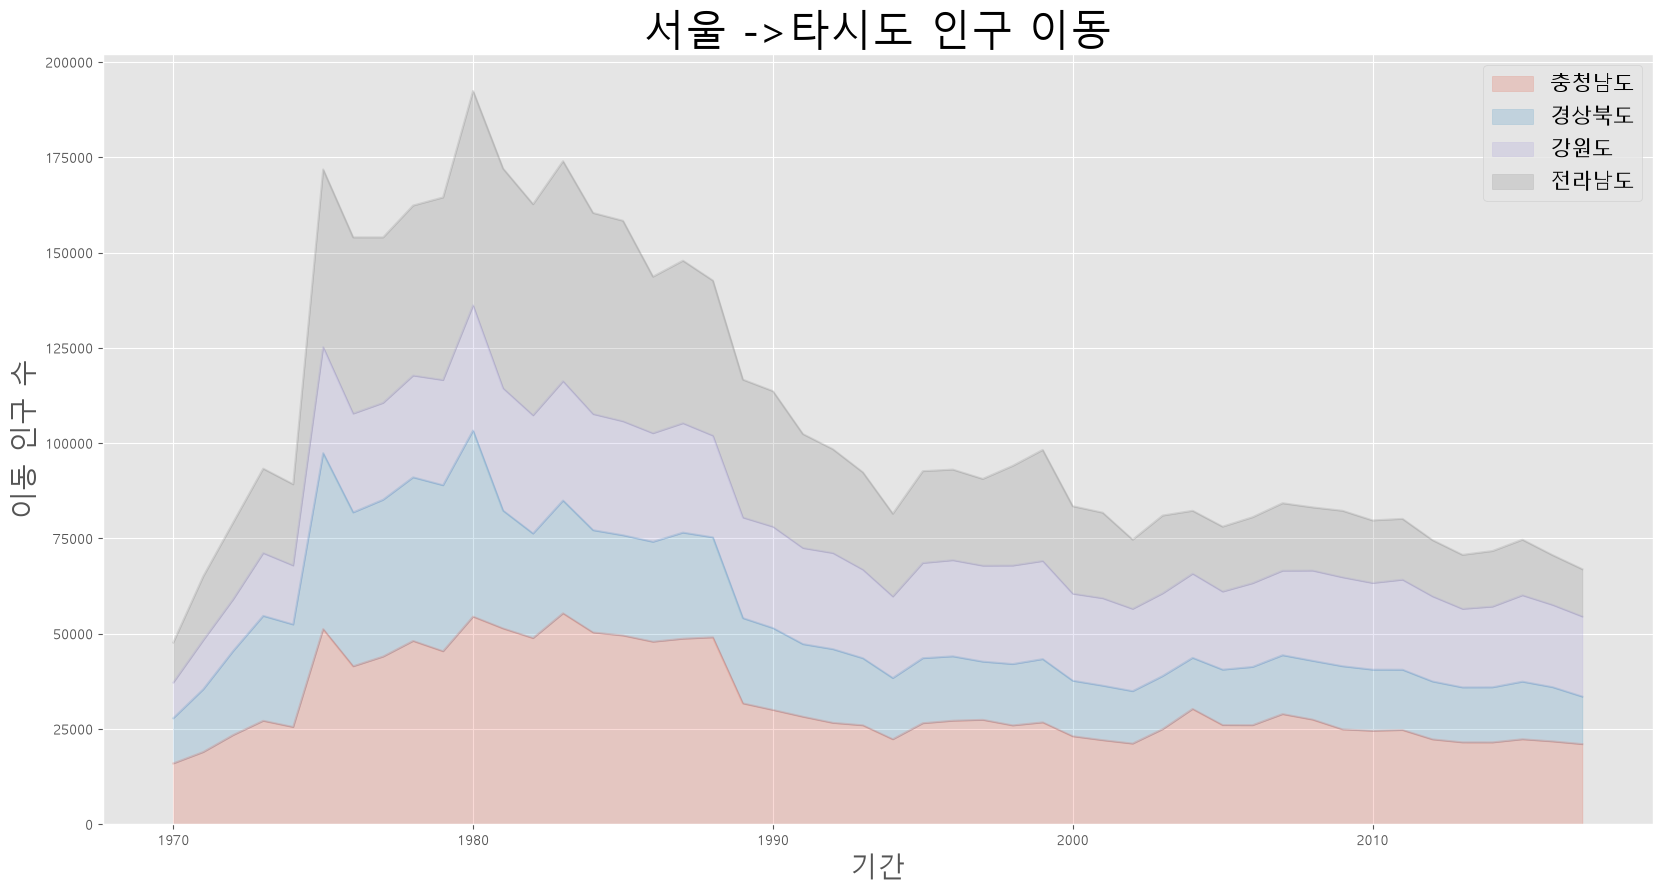

In [100]:
# 서울에서 '충청남도','경상북도', '강원도', '전라남도'로 이동한 인구 데이터 값만 선택
col_years = list(map(str, range(1970, 2018)))
df_4 = df_seoul.loc[['충청남도','경상북도', '강원도', '전라남도'], col_years]
df_4 = df_4.transpose()

df_4.index = df_4.index.map(int)

plt.style.use('ggplot')

# 면적 그래프 그리기
# stacked=True : 데이터 누적(기본값), stacked=False : 데이터 누적 안함
df_4.plot(kind='area', stacked=True, alpha=0.2, figsize=(20, 10))

plt.title('서울 ->타시도 인구 이동' , size=30)
plt.ylabel('이동 인구 수', size=20)
plt.xlabel('기간', size=20)
plt.legend(loc='best', fontsize=15)

plt.show()

* 막대그래프
   * barh

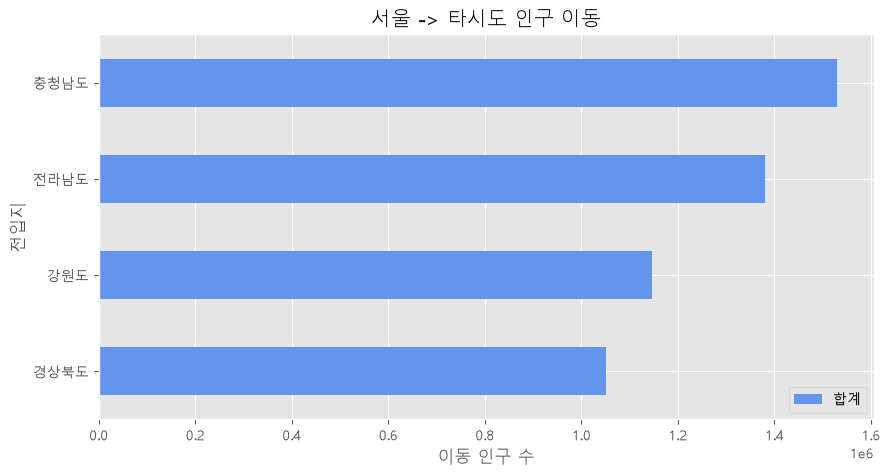

In [102]:
### 서울에서 '충청남도','경상북도', '강원도'로 이동한 인구 데이터 값만 선택
df_4 = col_years = list(map(str, range(1970,2018)))
df_4 = df_seoul.loc[['충청남도','경상북도','강원도','전라남도'], col_years]
df_4['합계'] = df_4.sum(axis=1)
df_4.head()

df_total = df_4[['합계']].sort_values(by='합계', ascending=True)
df_total.head()

#수평 막대 그래프 그리기
df_total.plot(kind='barh', color='cornflowerblue', width = 0.5 , figsize=(10,5))
plt.title('서울 -> 타시도 인구 이동')
plt.ylabel('전입지')
plt.xlabel('이동 인구 수')

plt.show()

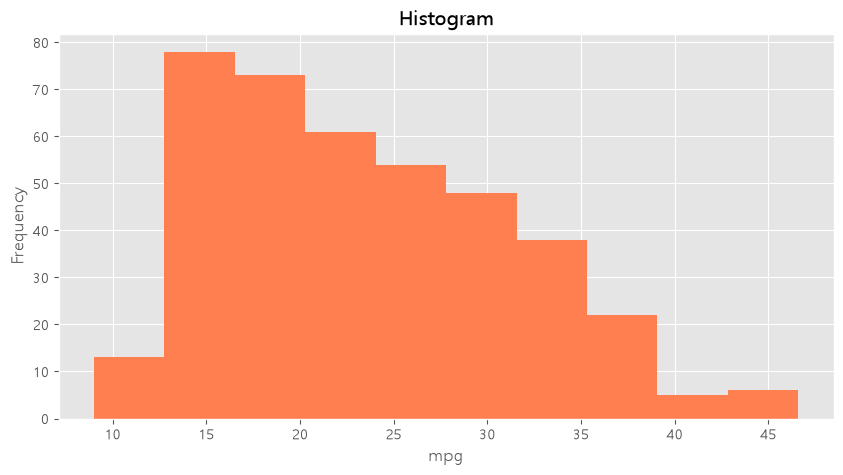

In [107]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc

font_path = "./Data-Pandas/malgun.ttf" #폰트파일의 위치
font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)

df = pd.read_csv('./Data-Pandas/auto-mpg.csv', header=None)

df.columns = ['mpg','cylinders','displacement','horsepower','weight',
              'acceleration','model year','origin','name']

df['mpg'].plot(kind='hist', bins=10, color='coral',figsize=(10,5))

plt.title('Histogram')
plt.xlabel('mpg')
plt.show()

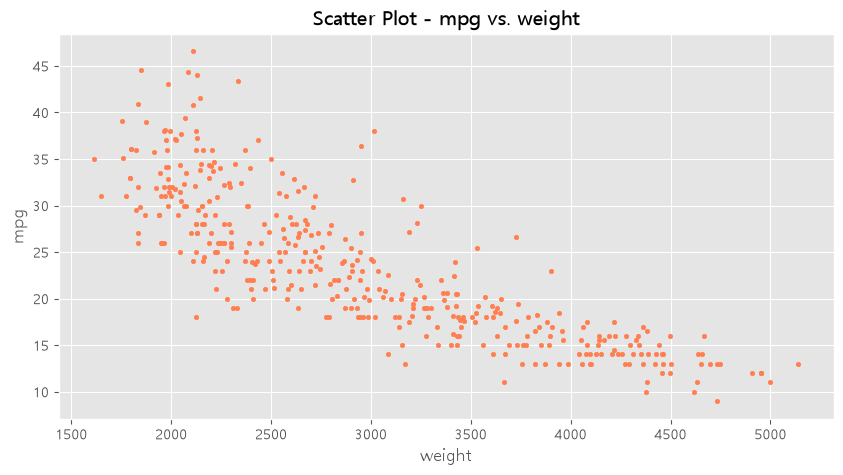

In [108]:
# 연비(mpg)와 차중(weight) 열에 대한 산점도 그리기
df.plot(kind='scatter', x='weight', y= 'mpg',c = 'coral',s=10,figsize=(10,5))
plt.title("Scatter Plot - mpg vs. weight")
plt.show()

* 버블 차트

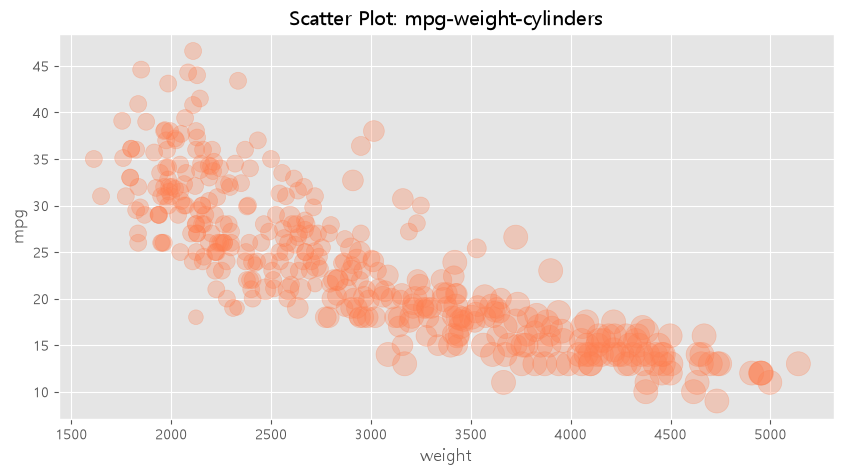

In [110]:
# 3개의 변수로 산점도 그리기
# cylinders 개수의 상대적 비율을 계산하여 점 크기로 사용
cylinders_size = df['cylinders'] / df['cylinders'].max() * 300

df.plot(kind='scatter', x='weight', y= 'mpg',c = 'coral' ,figsize=(10,5),
        s=cylinders_size, alpha=0.3)
plt.title("Scatter Plot: mpg-weight-cylinders")

plt.savefig("./output/scatter.png")
plt.savefig("./output/scatter_transparent.png",transparent=True)
plt.show()

* 파이차트

In [111]:
df.groupby('origin')

In [117]:
df['count'] =1
df_origin = df.groupby('origin').sum()
df_origin.head()
# for origin, data in df.groupby('origin'):
#     print(origin)
#     print(data)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,name,count
origin,,,,,,,,,
1,5000.8,1556,61229.5,130.0165.0150.0150.0140.0198.0220.0215.0225.01...,837121.0,3743.4,18827,chevrolet chevelle malibubuick skylark 320plym...,249
2,1952.4,291,7640.0,46.0087.0090.0095.00113.090.0070.0076.0060.005...,169631.0,1175.1,5307,volkswagen 1131 deluxe sedanpeugeot 504audi 10...,70
3,2405.6,324,8114.0,95.0088.0088.0095.0065.0069.0095.0097.0092.009...,175477.0,1277.6,6118,toyota corona mark iidatsun pl510datsun pl510t...,79


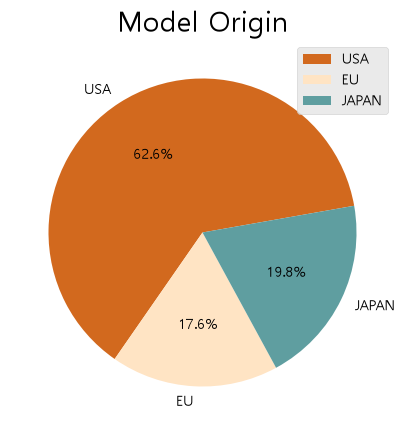

In [118]:
df_origin.index = ['USA', 'EU', 'JAPAN']
df_origin['count'].plot(kind='pie',
                        figsize=(7, 5),
                        autopct='%1.1f%%',   # 퍼센트 % 표시
                        startangle=10,       # 파이 조각을 나누는 시작점(각도 표시)
                        colors=['chocolate', 'bisque', 'cadetblue']    # 색상 리스트
                        )

plt.title('Model Origin', size=20)
plt.legend(labels=df_origin.index, loc='upper right')
plt.show()

* 박스 플롯
 * 범주형 데이터의 분포를 파악하는데 적합

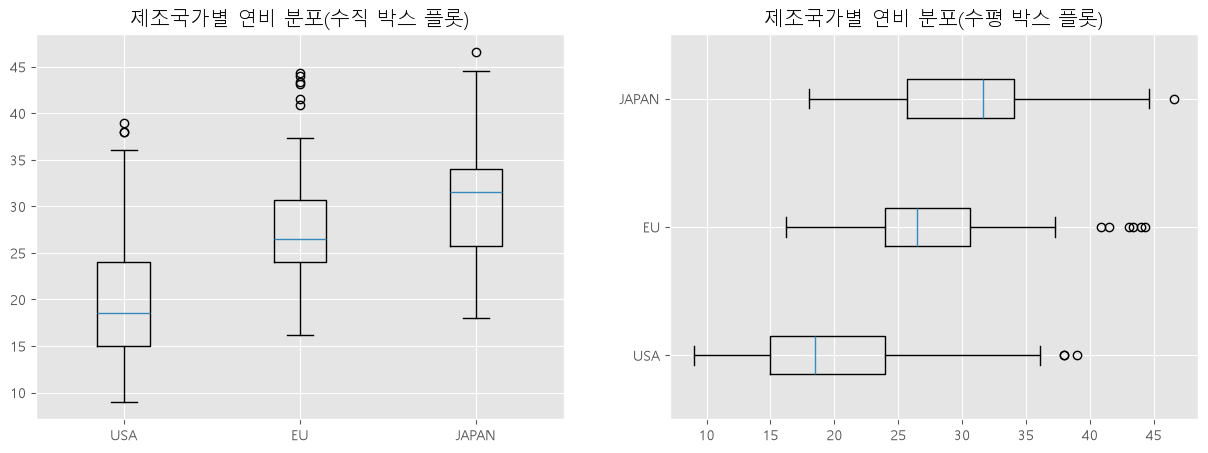

In [121]:
plt.style.use('ggplot')                      # 회색 배경 + 흰 격자선 스타일
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 부호 깨짐 방지

# 그래프 객체 생성 : 도화지 1장을 1행 2열로 나눠 그래프 2개
fig = plt.figure(figsize=(15,5))
ax1 = fig.add_subplot(1,2,1)   # 왼쪽
ax2 = fig.add_subplot(1,2,2)   # 오른쪽

# 왼쪽 : 수직 박스 플롯
#   x = 제조국가(origin)별 연비(mpg) 시리즈 3개 (1 = USA, 2 = EU, 3 = JAPAN) → 상자 3개
#   tick_labels = 상자마다 붙일 이름 (예전 matplotlib 에서는 labels= 였음)
ax1.boxplot(x=[df[df['origin']==1]['mpg'],
               df[df['origin']==2]['mpg'],
               df[df['origin']==3]['mpg']],
            tick_labels=['USA', 'EU', 'JAPAN'])

# 오른쪽 : 수평 박스 플롯
#   orientation='horizontal' = 상자를 가로로 눕힘 (예전 matplotlib 에서는 vert=False 였음)
ax2.boxplot(x=[df[df['origin']==1]['mpg'],
               df[df['origin']==2]['mpg'],
               df[df['origin']==3]['mpg']],
            tick_labels=['USA', 'EU', 'JAPAN'],
            orientation='horizontal')

ax1.set_title('제조국가별 연비 분포(수직 박스 플롯)')
ax2.set_title('제조국가별 연비 분포(수평 박스 플롯)')

plt.show()